In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import random, os

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [5]:
import os

# Ensure the fonts are installed
!apt-get install -y fonts-dejavu-core > /dev/null

# Four mathematical symbol classes
symbols = ['+', '-', 'x', '÷']
class_names = ['Plus', 'Minus', 'Multiplication', 'Division']

IMG_SIZE = 28
SAMPLES_PER_CLASS = 1500

X = []
y = []

font_paths = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"
]

for label, symbol in enumerate(symbols):
    for i in range(SAMPLES_PER_CLASS):
        img = Image.new("L", (64, 64), color=255)
        draw = ImageDraw.Draw(img)

        font_path = random.choice(font_paths)
        font_size = random.randint(28, 48)

        try:
            font = ImageFont.truetype(font_path, font_size)
        except OSError:
            # Fallback to default if there is still an issue
            font = ImageFont.load_default()

        # Draw symbol near the center
        bbox = draw.textbbox((0, 0), symbol, font=font)
        w = bbox[2] - bbox[0]
        h = bbox[3] - bbox[1]

        x_pos = (64 - w) // 2 - bbox[0] + random.randint(-3, 3)
        y_pos = (64 - h) // 2 - bbox[1] + random.randint(-3, 3)

        draw.text((x_pos, y_pos), symbol, fill=0, font=font)

        # Small rotation variation
        angle = random.uniform(-12, 12)
        img = img.rotate(angle, fillcolor=255)

        # Resize to 28x28
        img = img.resize((IMG_SIZE, IMG_SIZE))
        arr = np.array(img, dtype=np.uint8)

        # Add slight pixel noise
        noise = np.random.normal(0, 5, arr.shape)
        arr = np.clip(arr.astype(float) + noise, 0, 255).astype(np.uint8)

        X.append(arr)
        y.append(label)

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int64)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Total images:", len(X))
print("Classes:", class_names)

Dataset shape: (6000, 28, 28)
Labels shape: (6000,)
Total images: 6000
Classes: ['Plus', 'Minus', 'Multiplication', 'Division']


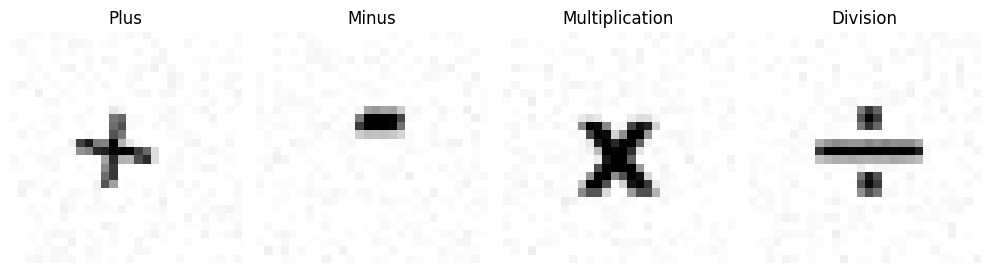

In [6]:
plt.figure(figsize=(10, 4))

for i, symbol in enumerate(symbols):
    index = np.where(y == i)[0][0]

    plt.subplot(1, 4, i + 1)
    plt.imshow(X[index], cmap="gray")
    plt.title(class_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Normalize pixel values from 0-255 to 0-1
X = X.astype("float32") / 255.0

# Add channel dimension for CNN
X = X[..., np.newaxis]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (4800, 28, 28, 1)
Testing images: (1200, 28, 28, 1)


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,868 (1.61 MB)

 Trainable params: 420,868 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.6338 - loss: 0.8885 - val_accuracy: 0.8611 - val_loss: 0.3437
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step - accuracy: 0.8936 - loss: 0.2641 - val_accuracy: 0.9931 - val_loss: 0.1177
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - accuracy: 0.9772 - loss: 0.0910 - val_accuracy: 0.9972 - val_loss: 0.0358
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.9917 - loss: 0.0387 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - accuracy: 0.9961 - loss: 0.0206 - val_accuracy: 0.9986 - val_loss: 0.0077
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.9985 - loss: 0.0126 - val_accuracy: 1.0000 - val_loss: 0.0040
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.9990 - loss: 0.0093 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.9990 - loss: 0.0069 - val_accuracy: 1.0000

In [10]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0012
Test Accuracy: 100.00%


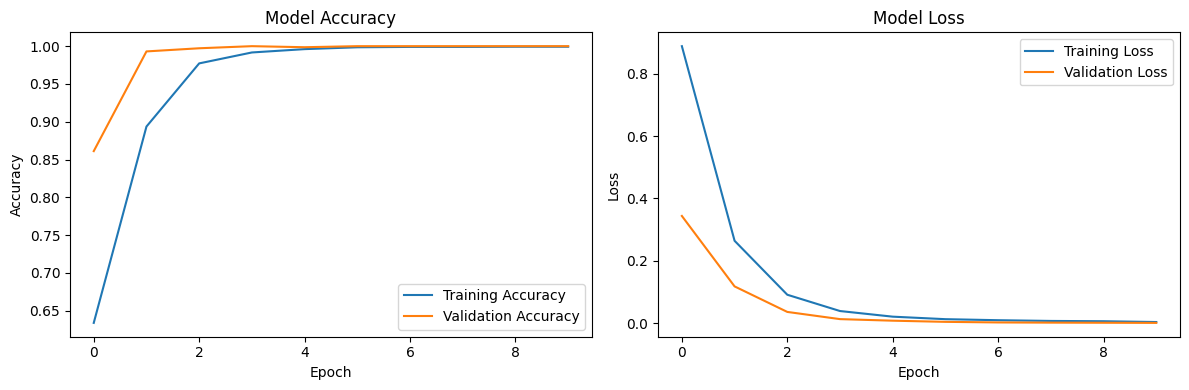

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Classification Report:

                precision    recall  f1-score   support

          Plus       1.00      1.00      1.00       300
         Minus       1.00      1.00      1.00       300
Multiplication       1.00      1.00      1.00       300
      Division       1.00      1.00      1.00       300

      accuracy                           1.00      1200
     macro avg       1.00      1.00      1.00      1200
  weighted avg       1.00      1.00      1.00      1200



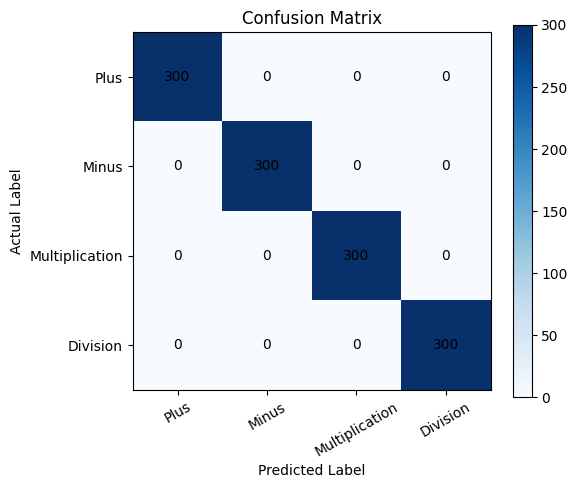

In [13]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(4), class_names, rotation=30)
plt.yticks(range(4), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.colorbar()

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

Saving Bold Black Plus Symbol.png to Bold Black Plus Symbol (1).png


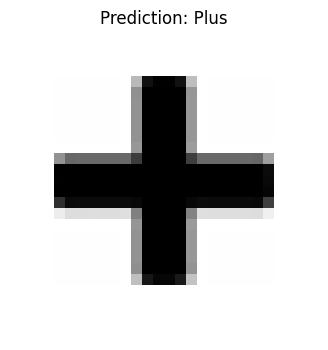

Predicted symbol: +
Confidence: 100.00%

Class probabilities:
Plus: 100.00%
Minus: 0.00%
Multiplication: 0.00%
Division: 0.00%


In [15]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

def preprocess_uploaded_image(filename):
    img = Image.open(filename).convert("L")

    # Convert to white background and dark ink
    arr = np.array(img)

    if arr.mean() < 127:
        arr = 255 - arr

    # Find dark pixels to crop around the symbol
    mask = arr < 180
    coords = np.argwhere(mask)

    if len(coords) == 0:
        raise ValueError("No visible symbol found. Upload a clearer image.")

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    cropped = Image.fromarray(arr).crop(
        (x_min, y_min, x_max + 1, y_max + 1)
    )

    # Fit symbol inside a 20x20 area
    cropped.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 255)
    x_offset = (28 - cropped.width) // 2
    y_offset = (28 - cropped.height) // 2
    canvas.paste(cropped, (x_offset, y_offset))

    return np.array(canvas, dtype="float32") / 255.0

processed = preprocess_uploaded_image(filename)

prediction = model.predict(
    processed[np.newaxis, ..., np.newaxis],
    verbose=0
)[0]

predicted_label = int(np.argmax(prediction))

plt.figure(figsize=(4, 4))
plt.imshow(processed, cmap="gray")
plt.title(f"Prediction: {class_names[predicted_label]}")
plt.axis("off")
plt.show()

print("Predicted symbol:", symbols[predicted_label])
print(f"Confidence: {prediction[predicted_label] * 100:.2f}%")
print("\nClass probabilities:")

for name, probability in zip(class_names, prediction):
    print(f"{name}: {probability * 100:.2f}%")

Saving Bold Black Plus Symbol.png to Bold Black Plus Symbol.png


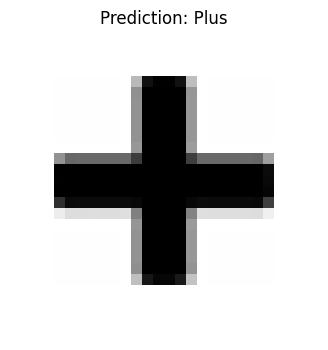

Predicted symbol: +
Confidence: 100.00%

Class probabilities:
Plus: 100.00%
Minus: 0.00%
Multiplication: 0.00%
Division: 0.00%


In [14]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

def preprocess_uploaded_image(filename):
    img = Image.open(filename).convert("L")

    # Convert to white background and dark ink
    arr = np.array(img)

    if arr.mean() < 127:
        arr = 255 - arr

    # Find dark pixels to crop around the symbol
    mask = arr < 180
    coords = np.argwhere(mask)

    if len(coords) == 0:
        raise ValueError("No visible symbol found. Upload a clearer image.")

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    cropped = Image.fromarray(arr).crop(
        (x_min, y_min, x_max + 1, y_max + 1)
    )

    # Fit symbol inside a 20x20 area
    cropped.thumbnail((20, 20))

    canvas = Image.new("L", (28, 28), 255)
    x_offset = (28 - cropped.width) // 2
    y_offset = (28 - cropped.height) // 2
    canvas.paste(cropped, (x_offset, y_offset))

    return np.array(canvas, dtype="float32") / 255.0

processed = preprocess_uploaded_image(filename)

prediction = model.predict(
    processed[np.newaxis, ..., np.newaxis],
    verbose=0
)[0]

predicted_label = int(np.argmax(prediction))

plt.figure(figsize=(4, 4))
plt.imshow(processed, cmap="gray")
plt.title(f"Prediction: {class_names[predicted_label]}")
plt.axis("off")
plt.show()

print("Predicted symbol:", symbols[predicted_label])
print(f"Confidence: {prediction[predicted_label] * 100:.2f}%")
print("\nClass probabilities:")

for name, probability in zip(class_names, prediction):
    print(f"{name}: {probability * 100:.2f}%")